# 🚦 Dhaka Traffic Density Analyzer: YOLO11 + ByteTrack + congestion score

Detection alone is not the goal. This notebook **counts vehicles**, turns the counts into a **congestion score (0–100)** and a
**heatmap**, and counts unique vehicles in video with **ByteTrack**. The model knows local classes such as **rickshaw**,
**CNG**, **human hauler (leguna)** and **auto rickshaw**.

| Step | What happens |
|---|---|
| Data | **Dhaka-AI** (DatasetNinja, 3,953 images, 21 classes). 956 unlabeled images are **filtered out** |
| Clean | duplicate images removed, EXIF rotation fixed, boxes clipped, own train/val/test split (80/10/10) |
| Train | YOLO11 fine-tune on 2×T4, **checkpoints mirrored to your GCS bucket → resumes after a stop** |
| Analyze | per-class AP · congestion score + heatmap on images · ByteTrack counting on video |
| Ship | `.pt` / `.pth` / ONNX weights + Gradio demo (`app/`) |

**Kaggle settings:** GPU **T4 ×2** · Internet **On** · Add-ons → Google Cloud Services → Cloud Storage.
Runtime ≈ 2.5–3.5 h for 80 epochs (if a session stops, *Run All* again to resume).

## 1 · Setup

In [1]:
!pip install -q ultralytics lap gradio onnx onnxslim onnxruntime tabulate 2>&1 | tail -1
import glob, hashlib, json, os, re, shutil, sys, tarfile, threading, time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from ultralytics import YOLO, settings

for k in ("wandb", "mlflow", "comet", "clearml", "neptune", "dvc"):      # no external loggers
    try:
        settings.update({k: False})
    except Exception:
        pass
N_GPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.2/104.2 kB 3.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch 2.10.0+cu128 | GPUs: ['Tesla T4', 'Tesla T4']


## 2 · Config
Change only this cell.

In [2]:
CFG = dict(
    project_id="mimic-cxr-training",          # your GCP project (bucket for checkpoints)
    bucket="mimic-cxr-training-mimic-ckpt",   # reused private bucket; prefix keeps projects apart
    prefix="dhaka-traffic",
    use_gcs=True,
    model="yolo11s.pt",                       # yolo11n/s/m; s = good accuracy/speed on T4
    imgsz=960,                                # many small vehicles -> larger than the default 640
    epochs=80, patience=25,
    batch=16 * max(N_GPU, 1),                 # 16 per GPU
    cache="ram",                              # faster epochs; set False if RAM is short
    seed=42,
    video="",                                 # path to a traffic video (else auto-find in /kaggle/input)
    video_seconds=20,
    demo=True,                                # launch the Gradio demo at the end
)
OUT, RUNS, DATA = Path("outputs").resolve(), Path("runs").resolve(), Path("/tmp/dhaka_yolo")
for d in ("models", "results/figures", "app"):
    (OUT / d).mkdir(parents=True, exist_ok=True)
Path("app").mkdir(exist_ok=True)
NAME = f"{Path(CFG['model']).stem}-{CFG['imgsz']}"
print("run:", NAME, "| outputs ->", OUT)

run: yolo11s-960 | outputs -> /kaggle/working/outputs


## 3 · Checkpoint store
GCS bucket when the Kaggle add-on is attached, otherwise a local folder. A background thread copies `last.pt` / `best.pt` to the bucket every 2 minutes during training.

In [3]:
def gcs_credentials():
    if "KAGGLE_USER_SECRETS_TOKEN" not in os.environ:
        return None
    from kaggle_secrets import UserSecretsClient
    if "GCS" in os.environ.get("KAGGLE_KERNEL_INTEGRATIONS", "").upper().split(":"):
        from kaggle_gcp import KaggleKernelCredentials
        from kaggle_secrets import GcpTarget
        return KaggleKernelCredentials(target=GcpTarget.GCS)
    from google.oauth2.credentials import Credentials            # "Google Cloud SDK" add-on
    return Credentials.from_authorized_user_info(json.loads(UserSecretsClient().get_gcloud_credential()))


class Store:
    def __init__(self, cfg):
        self.prefix, self.bucket, self.local = cfg["prefix"], None, OUT / "store"
        if not cfg["use_gcs"]:
            return
        try:
            from google.api_core import exceptions as gexc
            from google.cloud import storage
            client = storage.Client(project=cfg["project_id"], credentials=gcs_credentials())
            b = client.bucket(cfg["bucket"])
            try:
                exists = b.exists()
            except gexc.Forbidden:
                exists = True
            if not exists:
                b.iam_configuration.uniform_bucket_level_access_enabled = True
                b.iam_configuration.public_access_prevention = "enforced"
                b = client.create_bucket(b, location="US")
            self.bucket = b
            print(f"✅ checkpoints -> gs://{cfg['bucket']}/{self.prefix}")
        except Exception as e:
            print(f"⚠️ GCS unavailable ({type(e).__name__}: {str(e)[:150]}) -> local {self.local}")

    def put(self, local, key):
        if self.bucket:
            self.bucket.blob(f"{self.prefix}/{key}").upload_from_filename(str(local), timeout=600)
        else:
            (self.local / key).parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(local, self.local / key)

    def get(self, key, local) -> bool:
        Path(local).parent.mkdir(parents=True, exist_ok=True)
        if self.bucket:
            bl = self.bucket.blob(f"{self.prefix}/{key}")
            if not bl.exists():
                return False
            bl.download_to_filename(str(local), timeout=600)
            return True
        src = self.local / key
        if src.exists() and src.resolve() != Path(local).resolve():
            shutil.copy2(src, local)
        return src.exists()


class Syncer(threading.Thread):
    """Mirrors the training run to the store while YOLO trains (works with multi-GPU DDP too)."""
    FILES = ("weights/last.pt", "weights/best.pt", "results.csv", "args.yaml")

    def __init__(self, run_dir, key, every=120):
        super().__init__(daemon=True)
        self.run_dir, self.key, self.every, self.seen, self.halt = Path(run_dir), key, every, {}, threading.Event()

    def sync(self):
        for f in self.FILES:
            p = self.run_dir / f
            if not p.exists() or self.seen.get(f) == p.stat().st_mtime:
                continue
            m = p.stat().st_mtime
            time.sleep(3)
            if p.stat().st_mtime != m:
                continue                                         # still being written -> next round
            tmp = Path("/tmp/sync") / f
            tmp.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, tmp)
            store.put(tmp, f"{self.key}/{Path(f).name}")
            self.seen[f] = m

    def run(self):
        while not self.halt.wait(self.every):
            try:
                self.sync()
            except Exception as e:
                print("sync warning:", type(e).__name__, str(e)[:120])

    def finish(self):
        self.halt.set()
        self.sync()


store = Store(CFG)

✅ checkpoints -> gs://mimic-cxr-training-mimic-ckpt/dhaka-traffic


## 4 · Get Dhaka-AI
Order: cached YOLO copy in your bucket → DatasetNinja archive (Supervisely format) → original Kaggle version (Pascal VOC). After the first run the cleaned dataset comes straight from the bucket.

In [4]:
CLASSES = ["car", "bus", "motorbike", "three wheelers (CNG)", "rickshaw", "truck", "pickup", "minivan", "suv", "van",
           "bicycle", "auto rickshaw", "human hauler", "wheelbarrow", "ambulance", "minibus", "taxi", "army vehicle",
           "scooter", "policecar", "garbagevan"]
KEY = {re.sub(r"[^a-z]", "", c.lower()): i for i, c in enumerate(CLASSES)}
NINJA_URL = ("https://www.dropbox.com/scl/fi/3apbbrlsd2fkkvq6xi088/dhaka-ai-DatasetNinja.tar"
             "?rlkey=4sa6qehntce2fdhpe3bvd4d3r&dl=1")
KAGGLE_ORIGINAL = "rifat963/dhakaai-dhaka-based-traffic-detection-dataset"
DATA_TAR = "data/dhaka_yolo_v1.tar"


def download(url, dst):
    import requests
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total, done, t0, mark = int(r.headers.get("content-length", 0)), 0, time.time(), 0
        with open(dst, "wb") as f:
            for chunk in r.iter_content(8 << 20):
                f.write(chunk)
                done += len(chunk)
                if total and done / total >= mark:
                    print(f"  {done / 1e9:.2f}/{total / 1e9:.2f} GB | {done / 1e6 / (time.time() - t0):.0f} MB/s")
                    mark += 0.2


RAW_STATS = Counter()


def parse_voc(x: Path):
    """Pascal VOC XML -> ElementTree root, or None for empty / non-XML / broken files."""
    b = x.read_bytes().lstrip(b"\xef\xbb\xbf \t\r\n\x00")
    if not b.startswith(b"<"):
        return None
    try:
        return ET.fromstring(b)
    except ET.ParseError:
        try:
            from lxml import etree as LET                        # tolerant parser for slightly broken files
            r = LET.fromstring(b, LET.XMLParser(recover=True))
            return None if r is None else ET.fromstring(LET.tostring(r))
        except Exception:
            return None


def raw_items():
    """Yields (image_path, [(class_name, x1, y1, x2, y2), ...]) from whichever source is available."""
    raw = Path("/tmp/dhaka_raw")
    try:
        if not any(raw.rglob("*.json")):
            raw.mkdir(parents=True, exist_ok=True)
            print("Downloading DatasetNinja archive (~2 GB)...")
            download(NINJA_URL, "/tmp/dhaka.tar")
            with tarfile.open("/tmp/dhaka.tar") as t:
                t.extractall(raw, filter="data")
            os.remove("/tmp/dhaka.tar")
        anns = sorted(raw.rglob("ann/*.json"))
        if not anns:
            raise RuntimeError("archive has no ann/*.json files")
        print(f"Source: DatasetNinja (Supervisely) | {len(anns)} annotation files")
        for a in anns:
            d = json.loads(a.read_text())
            boxes = [(o["classTitle"], *o["points"]["exterior"][0], *o["points"]["exterior"][1])
                     for o in d.get("objects", []) if o.get("geometryType") == "rectangle"]
            yield a.parent.parent / "img" / a.name[:-5], boxes
        return
    except Exception as e:
        print(f"DatasetNinja failed ({type(e).__name__}: {str(e)[:150]}) -> original Kaggle version")
    import kagglehub
    root = Path(kagglehub.dataset_download(KAGGLE_ORIGINAL))
    imgs = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in (".jpg", ".jpeg", ".png"):
            imgs.setdefault(p.name.lower(), []).append(p)
    xmls = sorted(root.rglob("*.xml"))
    print(f"Source: Kaggle original (Pascal VOC) | {len(xmls)} XML files, {sum(map(len, imgs.values()))} images")

    def find_image(x, fname):
        names = [fname.lower()] if fname else []
        names += [x.stem.lower() + e for e in (".jpg", ".jpeg", ".png")]
        for n in names:
            cands = imgs.get(n, [])
            if cands:                                            # prefer the image closest to the XML
                return min(cands, key=lambda c: len(set(c.parts) ^ set(x.parts)))
        return None

    for x in xmls:
        t = parse_voc(x)
        if t is None:
            RAW_STATS["unreadable XML (skipped)"] += 1
            continue
        img = find_image(x, (t.findtext("filename") or "").strip())
        if img is None:
            RAW_STATS["XML without image (skipped)"] += 1
            continue
        boxes = []
        for o in t.iter("object"):
            bb = o.find("bndbox")
            try:
                boxes.append((o.findtext("name"), *(float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))))
            except (AttributeError, TypeError, ValueError):
                RAW_STATS["broken box (skipped)"] += 1
        yield img, boxes

## 5 · Clean + convert to YOLO
Drops unlabeled images, exact duplicates and unknown class names; fixes EXIF rotation; clips boxes; splits 80/10/10 by image hash (so a duplicate can never land in two splits).

In [5]:
def build_yolo():
    shutil.rmtree(DATA, ignore_errors=True)                      # no leftovers from a crashed run
    stats, seen = Counter(), set()
    for s in ("train", "val", "test"):
        (DATA / "images" / s).mkdir(parents=True, exist_ok=True)
        (DATA / "labels" / s).mkdir(parents=True, exist_ok=True)
    for i, (img, boxes) in enumerate(raw_items()):
        stats["images"] += 1
        if not boxes:
            stats["unlabeled (dropped)"] += 1
            continue
        if not Path(img).exists():
            stats["missing file"] += 1
            continue
        h = hashlib.md5(Path(img).read_bytes()).hexdigest()
        if h in seen:
            stats["duplicate (dropped)"] += 1
            continue
        seen.add(h)
        try:
            im = Image.open(img)
            W, H = im.size
        except Exception:
            stats["unreadable"] += 1
            continue
        lines = []
        for name, x1, y1, x2, y2 in boxes:
            c = KEY.get(re.sub(r"[^a-z]", "", str(name).lower()))
            if c is None:
                stats[f"unknown class '{name}'"] += 1
                continue
            x1, x2 = sorted((min(max(x1, 0), W), min(max(x2, 0), W)))
            y1, y2 = sorted((min(max(y1, 0), H), min(max(y2, 0), H)))
            if x2 - x1 < 2 or y2 - y1 < 2:
                stats["tiny box (dropped)"] += 1
                continue
            lines.append(f"{c} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
        if not lines:
            stats["no valid box (dropped)"] += 1
            continue
        b = int(h, 16) % 100
        split = "train" if b < 80 else "val" if b < 90 else "test"
        stem = f"{i:05d}_{re.sub(r'[^A-Za-z0-9_-]', '_', Path(img).stem)[:40]}"
        dst = DATA / "images" / split / f"{stem}.jpg"
        if im.getexif().get(274, 1) != 1 or im.format != "JPEG":   # boxes are in raw pixels -> drop EXIF rotation
            im.convert("RGB").save(dst, quality=95)
            stats["re-encoded (EXIF/format)"] += 1
        else:
            shutil.copy2(img, dst)
        (DATA / "labels" / split / f"{stem}.txt").write_text("\n".join(lines) + "\n")
        stats[f"kept {split}"] += 1
    return stats


if not (DATA / "data.yaml").exists():
    if store.get(DATA_TAR, "/tmp/dhaka_yolo.tar"):
        print("Using cleaned dataset from the bucket")
        with tarfile.open("/tmp/dhaka_yolo.tar") as t:
            t.extractall(DATA.parent, filter="data")
    else:
        st = build_yolo() + RAW_STATS
        print(pd.Series(st).sort_index().to_string())
        (DATA / "data.yaml").write_text(
            f"path: {DATA}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
            + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
        with tarfile.open("/tmp/dhaka_yolo.tar", "w") as t:
            t.add(DATA, arcname=DATA.name)
        store.put("/tmp/dhaka_yolo.tar", DATA_TAR)
    Path("/tmp/dhaka_yolo.tar").unlink(missing_ok=True)

inst = pd.DataFrame({s: Counter(int(l.split()[0]) for f in (DATA / "labels" / s).glob("*.txt")
                                for l in f.read_text().split("\n") if l) for s in ("train", "val", "test")}).fillna(0)
inst = inst.astype(int).rename(index=dict(enumerate(CLASSES))).sort_values("train", ascending=False)
print({s: len(list((DATA / "images" / s).glob("*"))) for s in ("train", "val", "test")}, "images")
inst

DatasetNinja failed (ReadError: file could not be opened successfully:
- method gz: ReadError('not a gzip file')
- method bz2: ReadError('not a bzip2 file')
- method xz: ReadError('n) -> original Kaggle version
Source: Kaggle original (Pascal VOC) | 3003 XML files, 3953 images
duplicate (dropped)            1
images                      3002
kept test                    337
kept train                  2380
kept val                     283
no valid box (dropped)         1
re-encoded (EXIF/format)      12
tiny box (dropped)             5
unreadable XML (skipped)       1
{'train': 2380, 'val': 283, 'test': 337} images


,train,val,test
car,4330,580,565
rickshaw,2739,311,499
bus,2637,335,367
three wheelers (CNG),2411,276,301
motorbike,1746,253,284
truck,1189,118,183
pickup,936,140,147
minivan,719,103,113
suv,672,94,94
van,589,91,76


> Rare classes (ambulance, police car, army vehicle, garbage van) have very few boxes. Expect low AP there. Report it rather than hide it.

## 6 · Look at the labels

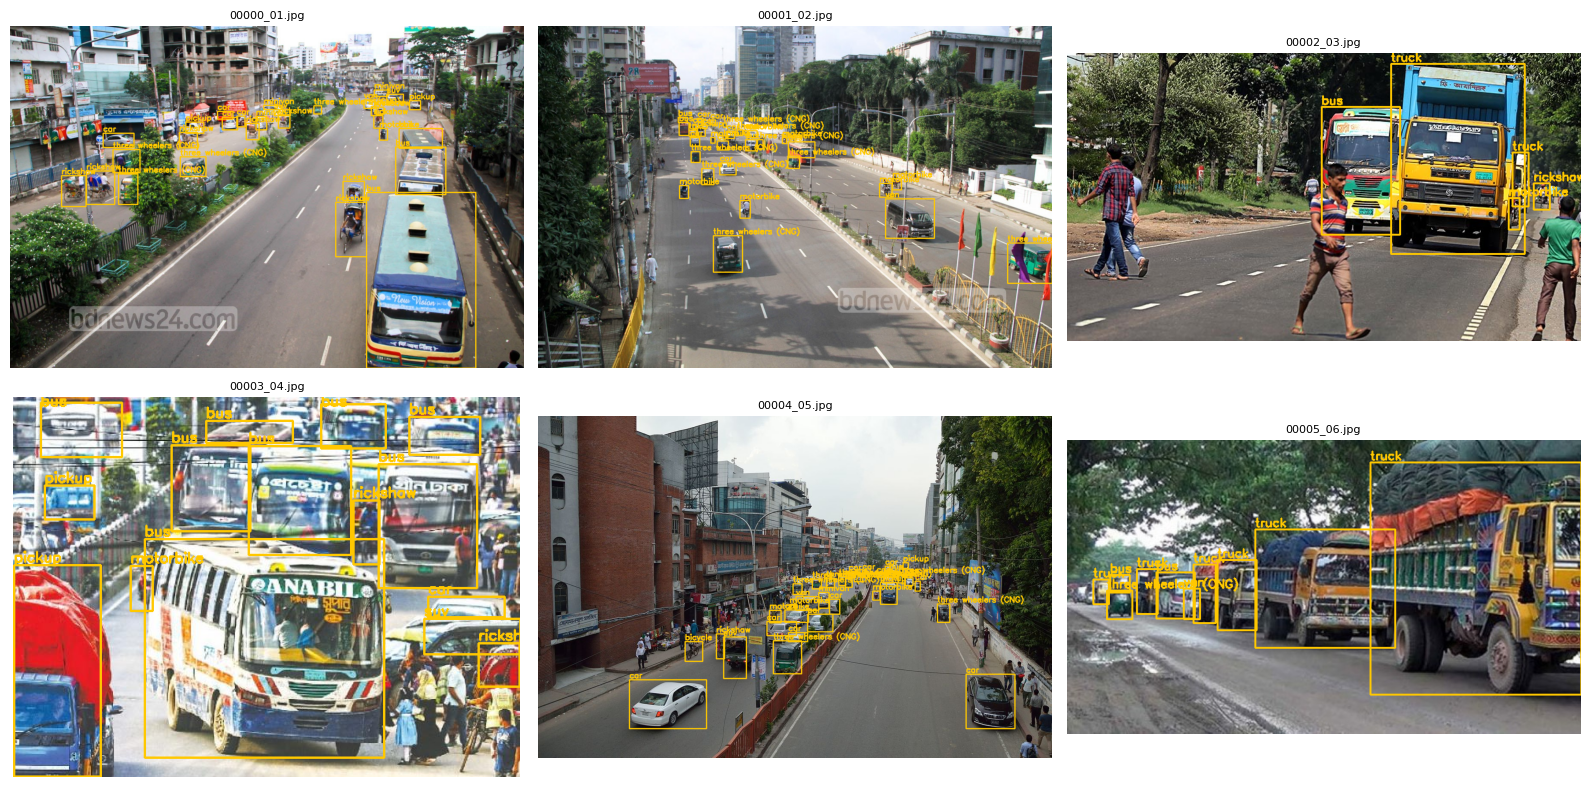

In [6]:
def draw_gt(p):
    img = cv2.imread(str(p))[..., ::-1].copy()
    H, W = img.shape[:2]
    for l in (DATA / "labels" / p.parent.name / f"{p.stem}.txt").read_text().split("\n"):
        if l:
            c, x, y, w, h = map(float, l.split())
            x1, y1, x2, y2 = int((x - w / 2) * W), int((y - h / 2) * H), int((x + w / 2) * W), int((y + h / 2) * H)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 200, 0), 2)
            cv2.putText(img, CLASSES[int(c)], (x1, max(12, y1 - 4)), 0, 0.6, (255, 200, 0), 2)
    return img


samples = sorted((DATA / "images/train").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, p in zip(axes.flat, samples):
    a.imshow(draw_gt(p)); a.set_title(p.name, fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

## 7 · Train YOLO11 (resumable)
- First run: starts from COCO-pretrained weights.
- After a stop: `last.pt` comes back from the bucket and training **continues from the same epoch**.
- Finished: a `DONE` marker is written, so later runs skip straight to evaluation.

In [7]:
RUN_DIR, CK = RUNS / NAME, f"ckpt/{NAME}"
W = RUN_DIR / "weights"
if store.get(f"{CK}/DONE.json", RUN_DIR / "DONE.json"):
    store.get(f"{CK}/best.pt", W / "best.pt"); store.get(f"{CK}/results.csv", RUN_DIR / "results.csv")
    print("✅ already trained:", json.loads((RUN_DIR / "DONE.json").read_text()))
else:
    resume = store.get(f"{CK}/last.pt", W / "last.pt")
    for f in ("results.csv", "args.yaml", "best.pt"):
        store.get(f"{CK}/{f}", (W if f.endswith(".pt") else RUN_DIR) / f)
    syncer = Syncer(RUN_DIR, CK)
    syncer.start()
    t0 = time.time()
    try:
        if resume:
            print("↻ resuming from bucket checkpoint")
            YOLO(str(W / "last.pt")).train(resume=True)
        else:
            YOLO(CFG["model"]).train(
                data=str(DATA / "data.yaml"), epochs=CFG["epochs"], imgsz=CFG["imgsz"], batch=CFG["batch"],
                device=list(range(N_GPU)) if N_GPU > 1 else 0 if N_GPU else "cpu", project=str(RUNS), name=NAME,
                exist_ok=True, patience=CFG["patience"], cos_lr=True, close_mosaic=10, cache=CFG["cache"], workers=4,
                seed=CFG["seed"], plots=True)
    except AssertionError as e:
        if "nothing to resume" not in str(e).lower() and "finished" not in str(e).lower():
            raise
        print("training had already finished:", e)
    finally:
        syncer.finish()
    done = {"epochs_csv_rows": len(pd.read_csv(RUN_DIR / "results.csv")), "minutes_this_session": round((time.time() - t0) / 60)}
    (RUN_DIR / "DONE.json").write_text(json.dumps(done))
    store.put(RUN_DIR / "DONE.json", f"{CK}/DONE.json")
    print("✅ training finished", done)

Ultralytics 8.4.219 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/dhaka_yolo/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, mu

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/80      9.43G      1.193      1.454      1.119         42        960: 100% ━━━━━━━━━━━━ 75/75 2.1it/s 35.7s0.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.8it/s 1.8s0.5s
                   all        283       2458      0.469      0.312      0.312       0.21

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/80      9.26G      1.182      1.326      1.117         75        960: 100% ━━━━━━━━━━━━ 75/75 2.0it/s 37.1s0.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.6it/s 1.9s0.5s
                   all        283       2458      0.427      0.366      0.301      0.194

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/80      9.35G      1.213      1.321      1.129         54        960: 100%

## 8 · Training curves

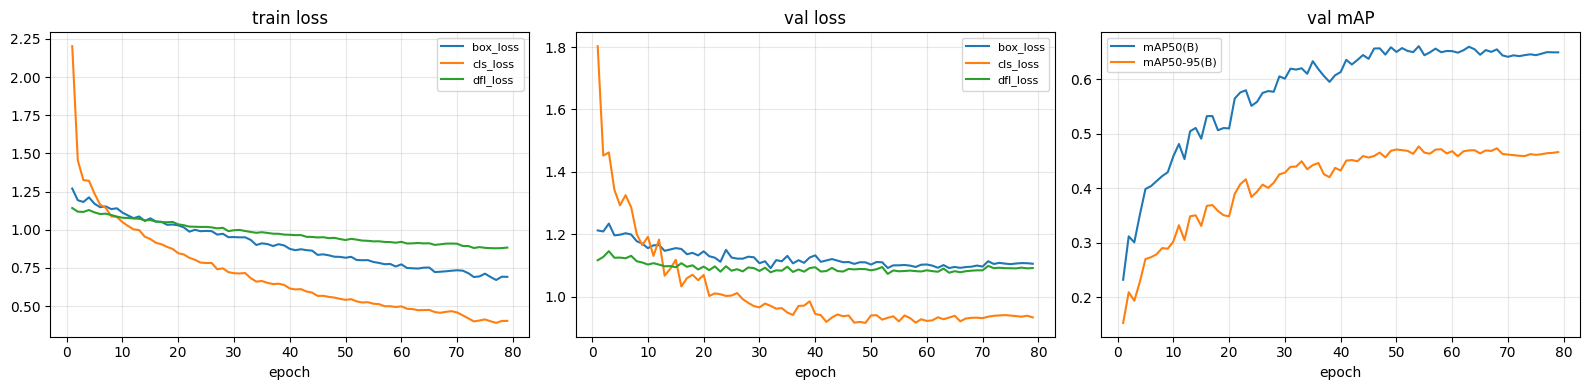

In [8]:
res = pd.read_csv(RUN_DIR / "results.csv")
res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for c in [c for c in res.columns if c.startswith("train/")]:
    ax[0].plot(res.epoch, res[c], label=c.split("/")[1])
for c in [c for c in res.columns if c.startswith("val/")]:
    ax[1].plot(res.epoch, res[c], label=c.split("/")[1])
for c in ("metrics/mAP50(B)", "metrics/mAP50-95(B)"):
    ax[2].plot(res.epoch, res[c], label=c.split("/")[1])
for a, t in zip(ax, ("train loss", "val loss", "val mAP")):
    a.set(title=t, xlabel="epoch"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "results/figures/training_curves.png", dpi=120); plt.show()

## 9 · Evaluate on the held-out test split

In [9]:
best = YOLO(str(W / "best.pt"))
m = best.val(data=str(DATA / "data.yaml"), split="test", imgsz=CFG["imgsz"], batch=16, device=0 if N_GPU else "cpu",
             project=str(RUNS), name=f"{NAME}-test", exist_ok=True, plots=True, verbose=False)
overall = {"mAP50": m.box.map50, "mAP50-95": m.box.map, "precision": m.box.mp, "recall": m.box.mr,
           "ms_per_image": m.speed["inference"]}
per_class = pd.DataFrame({"class": [CLASSES[i] for i in m.box.ap_class_index], "AP50": m.box.ap50,
                          "AP50-95": m.box.ap}).set_index("class")
per_class = per_class.join(inst[["train", "test"]].rename(columns=lambda c: f"boxes_{c}")).sort_values("AP50", ascending=False)
print(json.dumps({k: round(float(v), 4) for k, v in overall.items()}, indent=1))
per_class

Ultralytics 8.4.219 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,420,927 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3395.4±767.8 MB/s, size: 791.8 KB)
val: Scanning /tmp/dhaka_yolo/labels/test... 337 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 337/337 309.8it/s 1.1s5s
val: /tmp/dhaka_yolo/images/test/00077_161.jpg: corrupt JPEG restored and saved
val: /tmp/dhaka_yolo/images/test/00083_167.jpg: corrupt JPEG restored and saved
val: /tmp/dhaka_yolo/images/test/00085_169.jpg: corrupt JPEG restored and saved
val: /tmp/dhaka_yolo/images/test/00091_174.jpg: corrupt JPEG restored and saved
val: /tmp/dhaka_yolo/images/test/00095_178.jpg: corrupt JPEG restored and saved
val: /tmp/dhaka_yolo/images/test/00103_185.jpg: corrupt JPEG restored and saved
val: /tmp/dhaka_yolo/images/test/00644_Dipto_352.jpg: corrupt JPEG restored and saved
val: /tmp/dhaka_yolo/images/test/00659_Dipto_366.jpg: c

,AP50,AP50-95,boxes_train,boxes_test
class,,,,
three wheelers (CNG),0.820393,0.558906,2411,301
car,0.779605,0.545702,4330,565
bus,0.751320,0.516446,2637,367
motorbike,0.741484,0.423070,1746,284
truck,0.737577,0.546208,1189,183
rickshaw,0.682926,0.409746,2739,499
taxi,0.681188,0.402442,48,8
auto rickshaw,0.657292,0.420793,262,65
ambulance,0.607092,0.400976,51,6


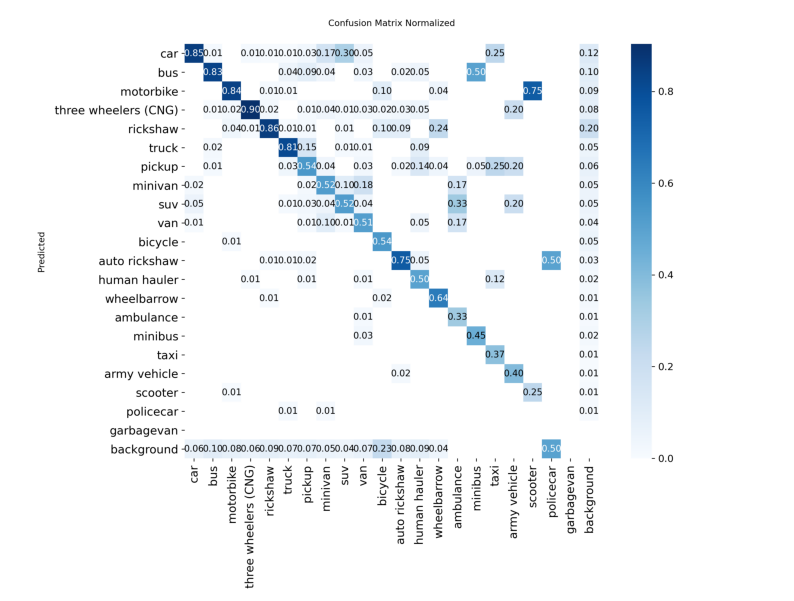

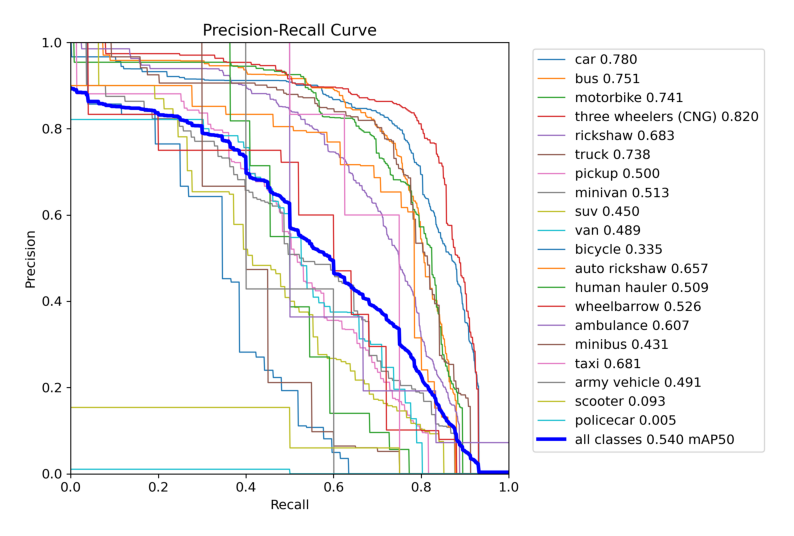

In [10]:
for f in ("confusion_matrix_normalized.png", "BoxPR_curve.png", "PR_curve.png"):
    p = Path(m.save_dir) / f
    if p.exists():
        shutil.copy2(p, OUT / "results/figures" / f)
        plt.figure(figsize=(10, 8)); plt.imshow(plt.imread(p)); plt.axis("off"); plt.show()

## 10 · Analyzer: counting, congestion score, heatmap
The same file powers the Gradio app. **Score** = occupancy (vehicle area / frame) + traffic load in PCU (bus = 3, car = 1, rickshaw = 1, motorbike = 0.5…), plus slowness for video. It is a transparent heuristic you can tune per camera, not a learned label.

In [11]:
%%writefile app/traffic.py
"""Dhaka traffic analyzer: vehicle counts, congestion score and heatmap for images; ByteTrack counting for video.

The congestion score is a transparent heuristic (0-100), not a learned quantity:
  image : 60% road occupancy (area covered by vehicles) + 40% traffic load in PCU
  video : 45% occupancy + 20% PCU load + 35% slowness (how little tracked vehicles move)
Every constant below can be changed for a given camera.
"""
from __future__ import annotations

import shutil
import subprocess
from collections import Counter
from pathlib import Path

import cv2
import numpy as np

# Approximate passenger-car-unit style weights (editable; heavier / slower vehicles load the road more)
PCU = {
    "car": 1.0, "taxi": 1.0, "suv": 1.0, "policecar": 1.0, "ambulance": 1.0, "van": 1.2, "minivan": 1.2,
    "pickup": 1.2, "minibus": 2.0, "bus": 3.0, "truck": 3.0, "garbagevan": 3.0, "army vehicle": 2.0,
    "three wheelers (CNG)": 0.8, "auto rickshaw": 0.8, "human hauler": 1.2, "rickshaw": 1.0,
    "motorbike": 0.5, "scooter": 0.5, "bicycle": 0.5, "wheelbarrow": 0.5,
}
OCC_JAM = 0.35      # vehicles covering 35% of the frame (or ROI) ~ jammed
PCU_JAM = 40.0      # 40 PCU in view ~ jammed
V_FREE = 0.010      # free-flow motion: 1% of the frame diagonal per frame
LEVELS = [(30, "Low"), (55, "Moderate"), (75, "Heavy"), (101, "Jam")]
COLORS = {"Low": (80, 175, 76), "Moderate": (0, 193, 255), "Heavy": (0, 120, 255), "Jam": (40, 40, 220)}  # BGR


def level(score: float) -> str:
    return next(name for t, name in LEVELS if score < t)


def occupancy(xyxy: np.ndarray, shape, roi=None, scale: int = 4) -> float:
    """Fraction of the frame (or ROI polygon) covered by the union of vehicle boxes."""
    h, w = shape[:2]
    m = np.zeros((max(1, h // scale), max(1, w // scale)), np.uint8)
    for x1, y1, x2, y2 in (np.asarray(xyxy, float).reshape(-1, 4) / scale).astype(int):
        m[max(0, y1):max(y2, y1 + 1), max(0, x1):max(x2, x1 + 1)] = 1
    if roi is None:
        return float(m.mean())
    r = np.zeros_like(m)
    cv2.fillPoly(r, [(np.asarray(roi, float) / scale).astype(np.int32)], 1)
    return float((m & r).sum() / max(int(r.sum()), 1))


def congestion(xyxy, names, shape, slow: float | None = None, roi=None) -> dict:
    occ = occupancy(xyxy, shape, roi)
    pcu = float(sum(PCU.get(n, 1.0) for n in names))
    o, p = min(occ / OCC_JAM, 1.0), min(pcu / PCU_JAM, 1.0)
    s = 100 * (0.6 * o + 0.4 * p) if slow is None else 100 * (0.45 * o + 0.2 * p + 0.35 * slow)
    return {"score": round(s, 1), "level": level(s), "occupancy": round(occ, 4), "pcu": round(pcu, 1)}


def heat_add(heat: np.ndarray, xyxy, weights, scale: int = 4) -> None:
    for (x1, y1, x2, y2), wt in zip((np.asarray(xyxy, float).reshape(-1, 4) / scale).astype(int), weights):
        heat[max(0, y1):max(y2, y1 + 1), max(0, x1):max(x2, x1 + 1)] += wt


def heat_overlay(img: np.ndarray, heat: np.ndarray, alpha: float = 0.45) -> np.ndarray:
    if heat.max() <= 0:
        return img.copy()
    h = cv2.GaussianBlur(heat, (0, 0), sigmaX=max(heat.shape) / 60)
    h = cv2.resize(h / h.max(), (img.shape[1], img.shape[0]))
    color = cv2.applyColorMap((h * 255).astype(np.uint8), cv2.COLORMAP_JET)
    a = (alpha * np.clip(h * 1.5, 0, 1))[..., None]
    return (img * (1 - a) + color * a).astype(np.uint8)


def banner(img: np.ndarray, lines: list[str], lvl: str) -> np.ndarray:
    out = img.copy()
    fs = max(0.5, img.shape[1] / 1600)
    th = int(28 * fs * 1.6)
    cv2.rectangle(out, (0, 0), (int(img.shape[1] * 0.42), th * len(lines) + 10), COLORS[lvl], -1)
    for i, t in enumerate(lines):
        cv2.putText(out, t, (10, th * (i + 1)), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), max(1, int(2 * fs)),
                    cv2.LINE_AA)
    return out


class Analyzer:
    def __init__(self, weights: str, imgsz: int = 960, conf: float = 0.25, device=None):
        from ultralytics import YOLO
        self.model = YOLO(weights)
        self.names = self.model.names
        self.imgsz, self.conf, self.device = imgsz, conf, device

    def _boxes(self, r):
        b = r.boxes
        xyxy = b.xyxy.cpu().numpy() if len(b) else np.zeros((0, 4))
        cls = [self.names[int(c)] for c in b.cls.cpu().numpy()] if len(b) else []
        return xyxy, cls

    def image(self, img_bgr: np.ndarray, roi=None) -> tuple[np.ndarray, np.ndarray, dict]:
        """Returns (annotated BGR, heatmap BGR, summary)."""
        r = self.model.predict(img_bgr, imgsz=self.imgsz, conf=self.conf, device=self.device, verbose=False)[0]
        xyxy, cls = self._boxes(r)
        c = congestion(xyxy, cls, img_bgr.shape, roi=roi)
        heat = np.zeros((max(1, img_bgr.shape[0] // 4), max(1, img_bgr.shape[1] // 4)), np.float32)
        heat_add(heat, xyxy, [PCU.get(n, 1.0) for n in cls])
        counts = dict(Counter(cls).most_common())
        ann = banner(r.plot(line_width=2, font_size=12), [f"Congestion {c['score']:.0f}/100  {c['level']}",
                                                          f"Vehicles {len(cls)} | PCU {c['pcu']:.0f}"], c["level"])
        return ann, heat_overlay(img_bgr, heat), {"vehicles": len(cls), "counts": counts, **c}

    def video(self, src: str, out_path: str, line: float = 0.6, max_frames: int | None = None, roi=None) -> dict:
        """ByteTrack over a video: unique vehicles, line-crossing counts, congestion timeline, heatmap video."""
        cap = cv2.VideoCapture(str(src))
        fps = cap.get(cv2.CAP_PROP_FPS) or 25
        w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        cap.release()
        tmp = str(Path(out_path).with_suffix(".raw.mp4"))
        writer = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
        ly, diag = line * h, float(np.hypot(w, h))
        heat = np.zeros((max(1, h // 4), max(1, w // 4)), np.float32)
        track_cls, prev, crossed, timeline, v_ema = {}, {}, {}, [], None
        stream = self.model.track(source=str(src), stream=True, persist=False, tracker="bytetrack.yaml",
                                  imgsz=self.imgsz, conf=self.conf, device=self.device, verbose=False)
        for i, r in enumerate(stream):
            if max_frames and i >= max_frames:
                break
            xyxy, cls = self._boxes(r)
            ids = r.boxes.id.int().cpu().tolist() if r.boxes.id is not None else []
            moves = []
            for tid, box, name in zip(ids, xyxy, cls):
                track_cls.setdefault(tid, name)
                cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
                if tid in prev:
                    px, py = prev[tid]
                    moves.append(np.hypot(cx - px, cy - py) / diag)
                    if (py - ly) * (cy - ly) < 0 and tid not in crossed:
                        crossed[tid] = track_cls[tid]
                prev[tid] = (cx, cy)
            if moves:
                v = float(np.median(moves))
                v_ema = v if v_ema is None else 0.9 * v_ema + 0.1 * v
            slow = None if v_ema is None else float(np.clip(1 - v_ema / V_FREE, 0, 1))
            c = congestion(xyxy, cls, (h, w), slow=slow, roi=roi)
            heat_add(heat, xyxy, [PCU.get(n, 1.0) for n in cls])
            timeline.append({"frame": i, "t": i / fps, "vehicles": len(cls), **c, "slowness": slow})
            fr = heat_overlay(r.plot(line_width=2, font_size=12), heat, alpha=0.35)
            cv2.line(fr, (0, int(ly)), (w, int(ly)), (255, 255, 255), 2)
            fr = banner(fr, [f"Congestion {c['score']:.0f}/100  {c['level']}",
                             f"In view {len(cls)} | unique {len(track_cls)} | crossed {len(crossed)}"], c["level"])
            writer.write(fr)
        writer.release()
        if shutil.which("ffmpeg"):       # H.264 so the video plays in browsers / Gradio
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", tmp, "-c:v", "libx264", "-preset", "veryfast",
                            "-pix_fmt", "yuv420p", "-movflags", "+faststart", out_path], check=True)
            Path(tmp).unlink(missing_ok=True)
        else:
            shutil.move(tmp, out_path)
        scores = [t["score"] for t in timeline] or [0]
        return {"frames": len(timeline), "fps": fps, "unique_vehicles": len(track_cls),
                "unique_by_class": dict(Counter(track_cls.values()).most_common()),
                "crossed_line": len(crossed), "crossed_by_class": dict(Counter(crossed.values()).most_common()),
                "mean_score": round(float(np.mean(scores)), 1), "peak_score": round(float(np.max(scores)), 1),
                "level": level(float(np.mean(scores))), "timeline": timeline, "heatmap": heat}

Writing app/traffic.py


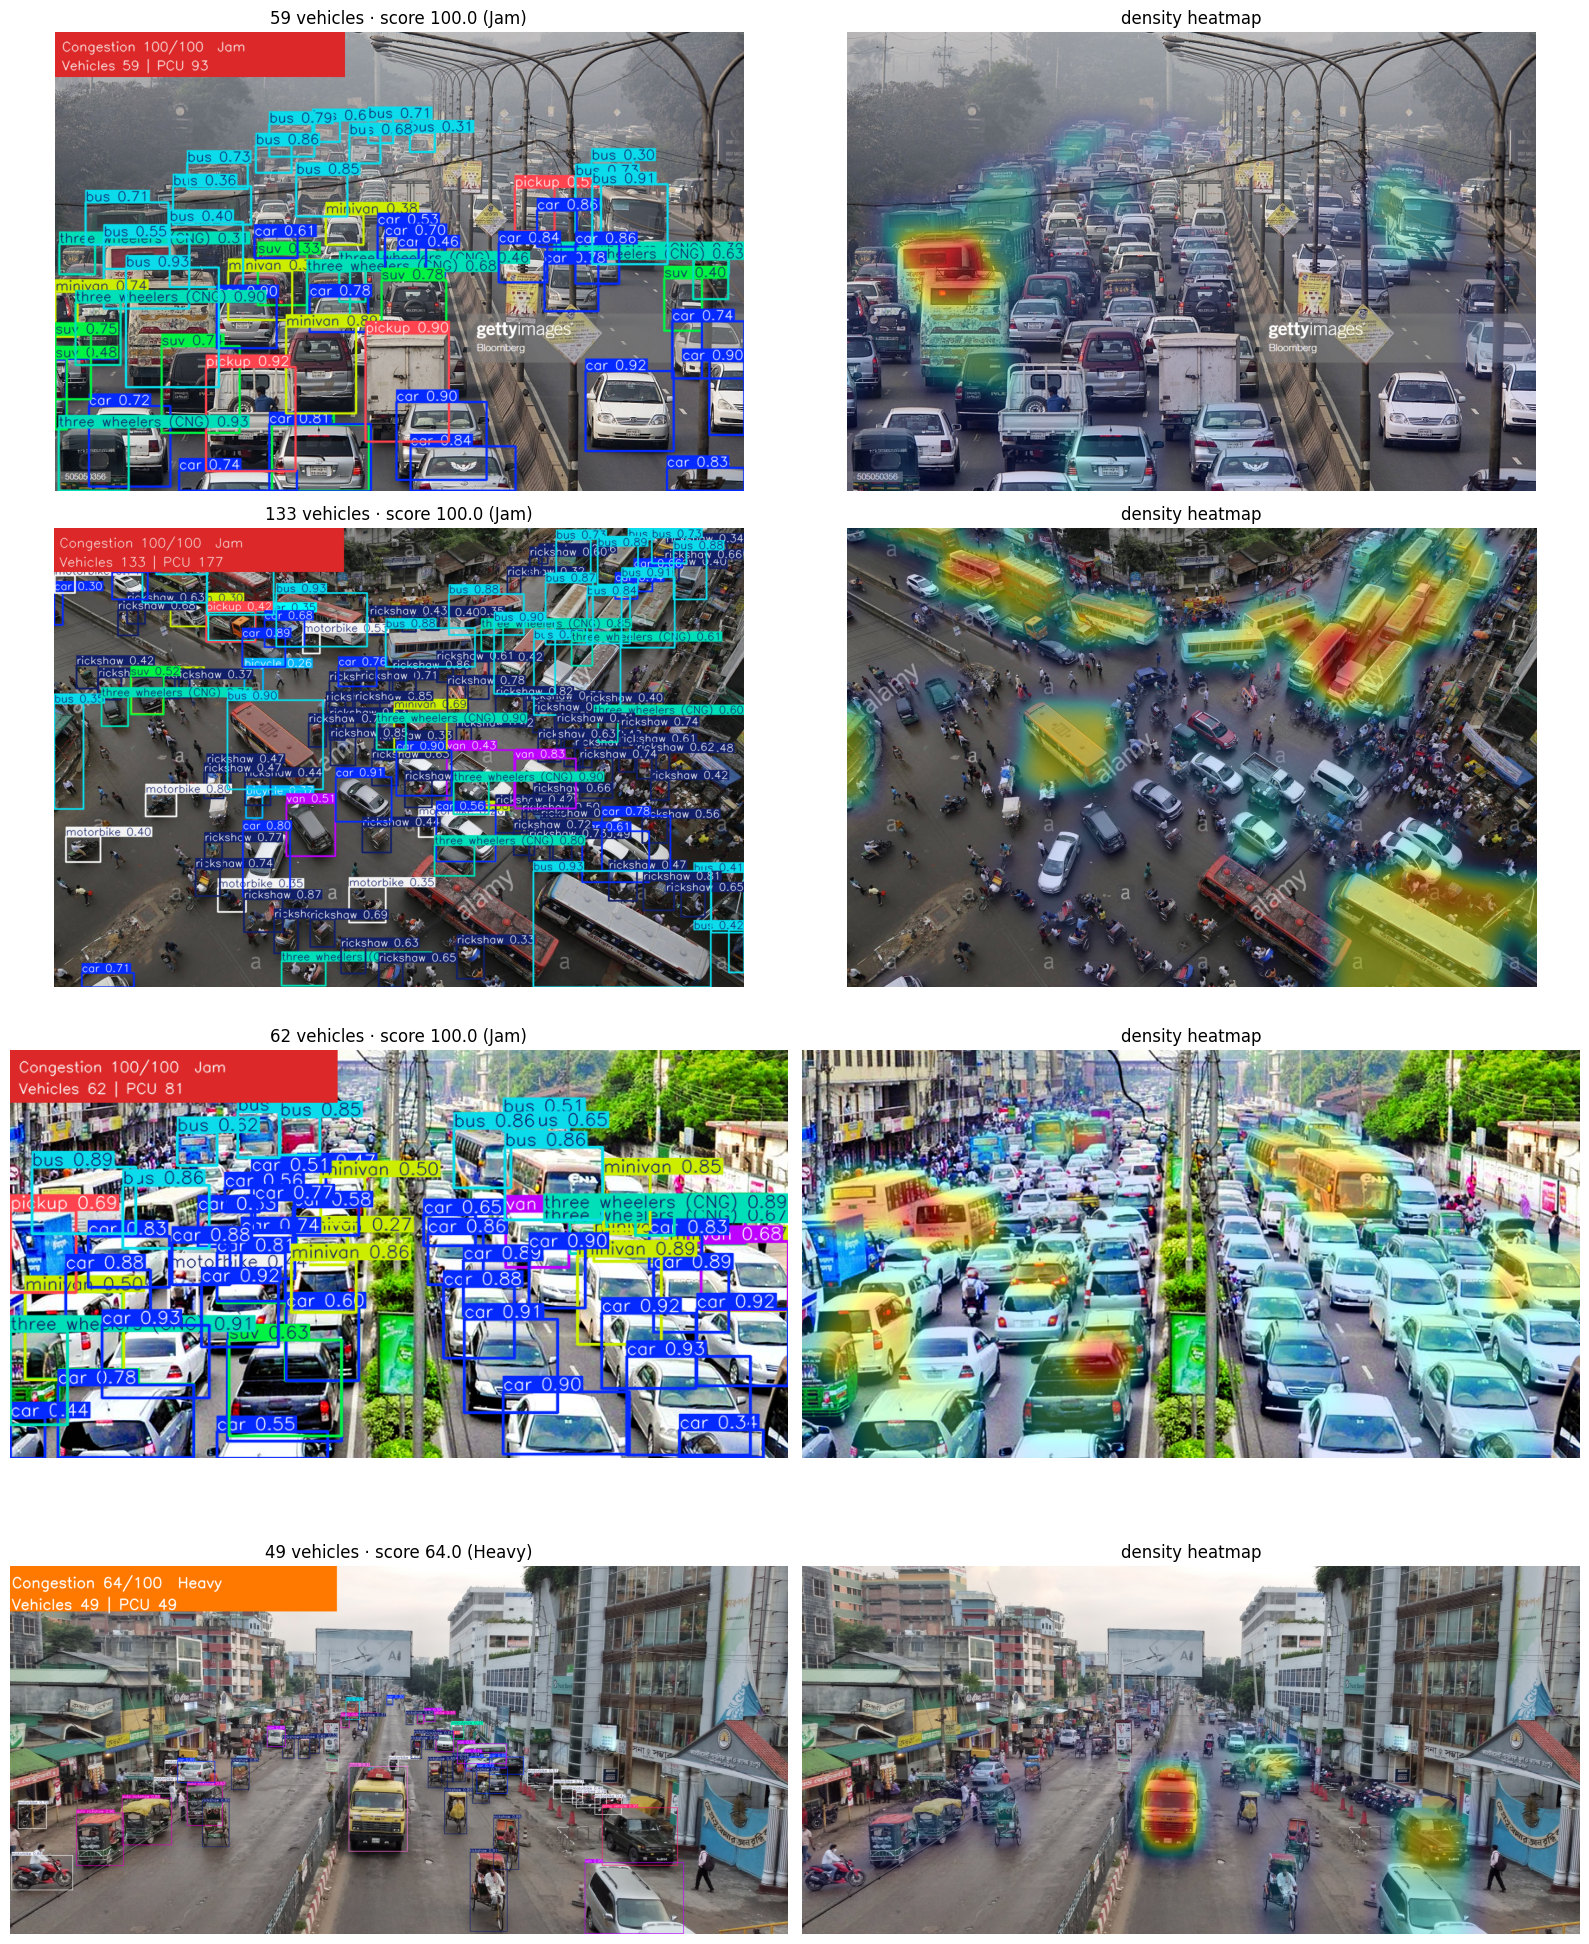

,image,vehicles,score,level,occupancy,pcu,top classes
0,00216_80.jpg,59,100.0,Jam,0.4360,93.0,"{'car': 21, 'bus': 17, 'three wheelers (CNG)':..."
1,00141_220.jpg,133,100.0,Jam,0.4747,176.9,"{'rickshaw': 67, 'bus': 24, 'car': 14, 'three ..."
2,00202_66.jpg,62,100.0,Jam,0.5667,81.3,"{'car': 31, 'bus': 9, 'minivan': 8, 'suv': 6}"
3,00659_Dipto_366.jpg,49,64.0,Heavy,0.1397,48.9,"{'rickshaw': 17, 'motorbike': 11, 'van': 6, 'a..."


In [12]:
for _m in ("traffic", "app"):
    sys.modules.pop(_m, None)                                    # always use the freshly written file
sys.path.insert(0, str(Path("app").resolve()))
from traffic import Analyzer

an = Analyzer(str(W / "best.pt"), imgsz=CFG["imgsz"], device=0 if N_GPU else "cpu")
test_imgs = sorted((DATA / "images/test").glob("*.jpg"), key=lambda p: -len((DATA / "labels/test" / f"{p.stem}.txt").read_text()))
rows = []
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for k, p in enumerate(test_imgs[:4]):
    ann, heat, s = an.image(cv2.imread(str(p)))
    rows.append({"image": p.name, **{k2: v for k2, v in s.items() if k2 != "counts"}, "top classes": dict(list(s["counts"].items())[:4])})
    axes[k, 0].imshow(ann[..., ::-1]); axes[k, 1].imshow(heat[..., ::-1])
    axes[k, 0].set_title(f"{s['vehicles']} vehicles · score {s['score']} ({s['level']})"); axes[k, 1].set_title("density heatmap")
    for a in axes[k]:
        a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "results/figures/image_analysis.jpg", dpi=80); plt.show()
pd.DataFrame(rows)

In [13]:
# Score distribution over the whole test split (sanity check of the heuristic)
scores = [an.image(cv2.imread(str(p)))[2] for p in test_imgs]
sd = pd.DataFrame(scores)
print(sd.level.value_counts().reindex(["Low", "Moderate", "Heavy", "Jam"]).fillna(0).astype(int).to_dict())
sd[["vehicles", "pcu", "occupancy", "score"]].describe().round(2)

{'Low': 161, 'Moderate': 64, 'Heavy': 88, 'Jam': 24}


,vehicles,pcu,occupancy,score
count,337.00,337.00,337.00,337.00
mean,8.49,11.34,0.21,38.70
std,10.88,13.97,0.21,25.49
min,0.00,0.00,0.00,0.00
25%,4.00,5.80,0.04,16.40
50%,6.00,8.40,0.13,32.20
75%,9.00,12.70,0.33,63.80
max,133.00,176.90,0.88,100.00


## 11 · Video: ByteTrack counting
Counts each vehicle **once** (unique track IDs), counts line crossings, and tracks congestion over time. Add your own Dhaka traffic clip with *Add Input* or set `CFG['video']`. Without a video, a short **synthetic pan** over a test image is used only to check that the pipeline runs.

source: /tmp/pan.mp4 (synthetic pan, sanity check only)
{
 "frames": 200,
 "fps": 25.0,
 "unique_vehicles": 108,
 "unique_by_class": {
  "bus": 24,
  "car": 22,
  "minivan": 19,
  "pickup": 15,
  "suv": 13,
  "three wheelers (CNG)": 12,
  "van": 1,
  "truck": 1,
  "rickshaw": 1
 },
 "crossed_line": 14,
 "crossed_by_class": {
  "car": 5,
  "suv": 4,
  "bus": 3,
  "minivan": 2
 },
 "mean_score": 93.2,
 "peak_score": 100.0,
 "level": "Jam"
}


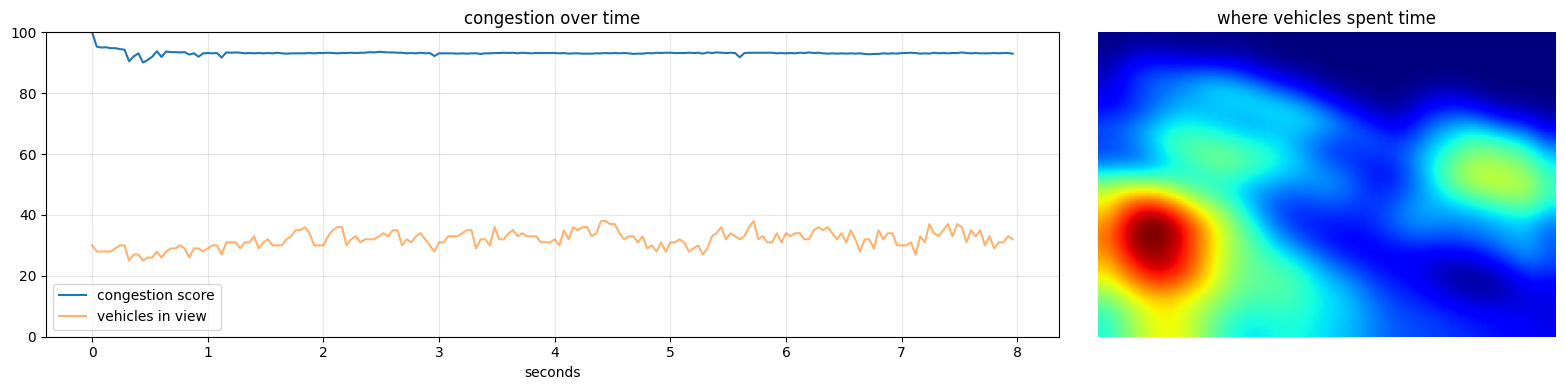

annotated video -> /kaggle/working/outputs/results/video_analyzed.mp4


In [14]:
def synthetic_pan(img_path, dst, seconds=8, fps=25):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]
    cw, ch = int(W * 0.7), int(H * 0.7)
    vw = cv2.VideoWriter(str(dst), cv2.VideoWriter_fourcc(*"mp4v"), fps, (cw, ch))
    for t in np.linspace(0, 1, seconds * fps):
        x, y = int(t * (W - cw)), int(0.5 * t * (H - ch))
        vw.write(np.ascontiguousarray(img[y:y + ch, x:x + cw]))
    vw.release()
    return str(dst)


VIDEO = CFG["video"] or next(iter(sorted(sum((glob.glob(f"/kaggle/input/**/*.{e}", recursive=True)
                                              for e in ("mp4", "avi", "mov", "mkv")), []))), "")
synthetic = not VIDEO
if synthetic:
    VIDEO = synthetic_pan(test_imgs[0], "/tmp/pan.mp4")
fps = cv2.VideoCapture(VIDEO).get(cv2.CAP_PROP_FPS) or 25
vid = an.video(VIDEO, str(OUT / "results/video_analyzed.mp4"), max_frames=int(CFG["video_seconds"] * fps))
print("source:", VIDEO, "(synthetic pan, sanity check only)" if synthetic else "")
print(json.dumps({k: v for k, v in vid.items() if k not in ("timeline", "heatmap")}, indent=1))
tl = pd.DataFrame(vid["timeline"])
fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(tl.t, tl.score, label="congestion score"); ax[0].plot(tl.t, tl.vehicles, label="vehicles in view", alpha=.6)
ax[0].set(xlabel="seconds", ylim=(0, max(100, tl.vehicles.max() + 5)), title="congestion over time"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].imshow(cv2.GaussianBlur(vid["heatmap"], (0, 0), 6), cmap="jet"); ax[1].set_title("where vehicles spent time"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(OUT / "results/figures/video_timeline.png", dpi=110); plt.show()
print("annotated video ->", OUT / "results/video_analyzed.mp4")

## 12 · Export weights: `.pt` · `.pth` · ONNX

In [15]:
tag = NAME.replace("-", "_")
shutil.copy2(W / "best.pt", OUT / f"models/dhaka_{tag}.pt")                           # Ultralytics checkpoint
torch.save({"state_dict": best.model.state_dict(), "names": CLASSES, "imgsz": CFG["imgsz"]},
           OUT / f"models/dhaka_{tag}_state_dict.pth")                                # plain PyTorch weights
onnx = YOLO(str(W / "best.pt")).export(format="onnx", imgsz=CFG["imgsz"], dynamic=False, simplify=True)
shutil.move(onnx, OUT / f"models/dhaka_{tag}.onnx")
shutil.copy2(W / "best.pt", OUT / "app/dhaka_yolo11s.pt")
for p in sorted((OUT / "models").iterdir()):
    print(f"{p.name:40s} {p.stat().st_size / 1e6:6.1f} MB")

Ultralytics 8.4.219 🚀 Python-3.12.12 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,420,927 parameters, 0 gradients, 48.6 GFLOPs

PyTorch: starting from '/kaggle/working/runs/yolo11s-960/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 25, 18900) (18.3 MB)

ONNX: starting export with onnx 1.20.1 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.2s, saved as '/kaggle/working/runs/yolo11s-960/weights/best.onnx' (36.4 MB)

Export complete (4.1s)
Results saved to /kaggle/working/runs/yolo11s-960/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs/yolo11s-960/weights/best.onnx imgsz=960 
Validate:        yolo val task=detect model=/kaggle/working/runs/yolo11s-960/weights/best.onnx imgsz=960 data=/tmp/dhaka_yolo/data.yaml

## 13 · Gradio demo
The same `app/` folder can be pushed to a Hugging Face Space (`app.py` + `traffic.py` + weights).

In [16]:
%%writefile app/app.py
"""Gradio demo: Dhaka traffic density analyzer (image + video). Run: python app.py"""
import os
import tempfile

import cv2
import gradio as gr
import pandas as pd

from traffic import Analyzer


def build_demo(an: Analyzer) -> gr.Blocks:
    def on_image(img_rgb):
        if img_rgb is None:
            return None, None, {}
        ann, heat, s = an.image(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))
        return cv2.cvtColor(ann, cv2.COLOR_BGR2RGB), cv2.cvtColor(heat, cv2.COLOR_BGR2RGB), s

    def on_video(path, seconds):
        if not path:
            return None, {}, None
        out = os.path.join(tempfile.mkdtemp(), "analyzed.mp4")
        fps = cv2.VideoCapture(path).get(cv2.CAP_PROP_FPS) or 25
        s = an.video(path, out, max_frames=int(seconds * fps))
        tl = pd.DataFrame(s.pop("timeline"))[["t", "score"]]
        s.pop("heatmap")
        return out, s, tl

    with gr.Blocks(title="Dhaka Traffic Density Analyzer") as demo:
        gr.Markdown("# 🚦 Dhaka Traffic Density Analyzer\nYOLO11 fine-tuned on Dhaka-AI (21 local vehicle classes, "
                    "incl. rickshaw and CNG) · congestion score 0–100 · heatmap · ByteTrack counting for video.")
        with gr.Tab("Image"):
            with gr.Row():
                inp = gr.Image(type="numpy", label="Traffic photo")
                out = gr.Image(label="Detections + score")
            with gr.Row():
                heat = gr.Image(label="Density heatmap")
                info = gr.JSON(label="Summary")
            gr.Button("Analyze", variant="primary").click(on_image, inp, [out, heat, info])
        with gr.Tab("Video"):
            with gr.Row():
                vin = gr.Video(label="Traffic video")
                vout = gr.Video(label="Tracked + heatmap")
            secs = gr.Slider(5, 120, value=20, step=5, label="Seconds to analyze")
            vinfo = gr.JSON(label="Counts")
            plot = gr.LinePlot(x="t", y="score", title="Congestion over time", y_lim=[0, 100])
            gr.Button("Analyze video", variant="primary").click(on_video, [vin, secs], [vout, vinfo, plot])
        gr.Markdown("Score = occupancy + PCU load (+ slowness for video). It is a heuristic; tune the constants in "
                    "`traffic.py` for a fixed camera.")
    return demo


if __name__ == "__main__":
    build_demo(Analyzer(os.environ.get("MODEL_PATH", "dhaka_yolo11s.pt"))).launch()

Writing app/app.py


In [17]:
%%writefile app/requirements.txt
ultralytics>=8.3
lap>=0.5
gradio>=4.44
opencv-python-headless
pandas

Writing app/requirements.txt


In [18]:
for f in ("app.py", "traffic.py"):
    shutil.copy2(Path("app") / f, OUT / "app" / f)
shutil.copy2("app/requirements.txt", OUT / "app/requirements.txt")
sys.modules.pop("app", None)
from app import build_demo

if CFG["demo"]:
    demo = build_demo(an)
    demo.launch(share=True, prevent_thread_lock=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://1249a61cdfe186cc5d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14 · Save results

In [23]:
import zipfile

summary = {"run": NAME, "config": CFG, "test": {k: float(v) for k, v in overall.items()},
           "per_class": per_class.reset_index().to_dict("records"),
           "data": {s: len(list((DATA / "images" / s).glob("*"))) for s in ("train", "val", "test")},
           "video": {k: v for k, v in vid.items() if k not in ("timeline", "heatmap")}, "video_synthetic": synthetic}
(OUT / "results/results.json").write_text(json.dumps(summary, indent=2, default=str))
h = pd.read_csv(RUN_DIR / "results.csv")                         # self-contained: does not need section 8's table
h.columns = [c.strip() for c in h.columns]
hc = [c for c in ("epoch", "train/box_loss", "val/box_loss", "metrics/precision(B)", "metrics/recall(B)",
                  "metrics/mAP50(B)", "metrics/mAP50-95(B)") if c in h]
hist_md = h[hc].rename(columns=lambda c: c.replace("metrics/", "").replace("(B)", "")).to_markdown(index=False, floatfmt=".4f")
with open(OUT / "results/RESULTS.md", "w") as f:
    f.write(f"## Test split ({summary['data']['test']} images)\n\n")
    f.write(pd.Series(overall).to_frame("value").to_markdown(floatfmt=".4f"))
    f.write("\n\n## Per class\n\n" + per_class.to_markdown(floatfmt=".3f") + "\n")
    f.write("\n\n## Training history\n\n" + hist_md + "\n")
shutil.copy2(RUN_DIR / "results.csv", OUT / "results/results.csv")

need = ["app/app.py", "app/traffic.py", "app/requirements.txt", "app/dhaka_yolo11s.pt", "results/RESULTS.md",
        "results/results.json", "results/results.csv"]
missing = [f for f in need if not (OUT / f).exists()]
assert not missing, f"missing: {missing} -> run sections 12-13 first"
assert any((OUT / "models").glob("*.pt")), "no model in outputs/models -> run section 12 first"

gh = Path.cwd() / "results_for_github.zip"                       # same layout as the repo
with zipfile.ZipFile(gh, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in ("models", "results", "app"):
        for p in sorted((OUT / sub).rglob("*")):
            if p.is_file():
                z.write(p, p.relative_to(OUT).as_posix())
with zipfile.ZipFile(gh) as z:
    assert z.testzip() is None, "zip is corrupt"
    names = z.namelist()

for p in [p for sub in ("results", "models") for p in (OUT / sub).rglob("*") if p.is_file()] + [gh]:
    store.put(p, f"final/{p.relative_to(OUT).as_posix() if p.is_relative_to(OUT) else p.name}")
print(f"✅ {gh.name}: {len(names)} files, {gh.stat().st_size / 1e6:.1f} MB  (also in the bucket under final/)")
for folder in ("models", "results", "app"):
    print(f"   {folder + '/':9s}", ", ".join(n.split("/", 1)[1] for n in names if n.startswith(folder + "/")))
print("Unzip results_for_github.zip into the repo folder (it fills models/, results/, app/).")
print("GitHub limit is 100 MB per file: commit the .pt; keep the .onnx / .pth as a Release asset if they are larger.")

✅ results_for_github.zip: 16 files, 94.9 MB  (also in the bucket under final/)
   models/   dhaka_yolo11s_960.onnx, dhaka_yolo11s_960.pt, dhaka_yolo11s_960_state_dict.pth
   results/  RESULTS.md, figures/BoxPR_curve.png, figures/confusion_matrix_normalized.png, figures/image_analysis.jpg, figures/training_curves.png, figures/video_timeline.png, results.csv, results.json, video_analyzed.mp4
   app/      app.py, dhaka_yolo11s.pt, requirements.txt, traffic.py
Unzip results_for_github.zip into the repo folder (it fills models/, results/, app/).
GitHub limit is 100 MB per file: commit the .pt; keep the .onnx / .pth as a Release asset if they are larger.
